# 03 – Modell Tanítás és 5-Fold Keresztvalidáció Fine-Tuninggal (Márka Osztályozás)

**Projekt:** Nike / Adidas / Converse cipőmárkák képosztályozása  
**Cél:** Magas pontosság (Accuracy és Macro F1) elérése előtanított **MobileNetV2** modellel, kétfázisú tanítással (fej betanítása + felső rétegek **Fine-Tuningja** alacsony tanulási rátával), **Stratified 5-Fold Keresztvalidációval** kiértékelve.

**Bemenet:** `../results/brand/dataset_with_folds.csv`  
**Kimenet:** Foldonkénti és aggregált kiértékelés, Confusion Matrix, mentett modell-súlyok.

## 1. Könyvtárak Betöltése és Hiperparaméterek

In [4]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Reprodukálhatóság
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Hiperparaméterek
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
INITIAL_EPOCHS = 10     # 1. fázis: csak az osztályozó fej tanítása
FINE_TUNE_EPOCHS = 15   # 2. fázis: felső konvolúciós rétegek finomhangolása
INITIAL_LR = 1e-3       # Kezdeti tanulási ráta (0.001)
FINE_TUNE_LR = 1e-5     # Alacsony tanulási ráta finomhangoláshoz (0.00001)
K_FOLDS = 5

PROJECT_ROOT = Path("..").resolve()
MANIFEST_PATH = PROJECT_ROOT / "results" / "brand" / "dataset_with_folds.csv"
MODEL_SAVE_DIR = PROJECT_ROOT / "results" / "models_brand"
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Manifest betöltése
manifest = pd.read_csv(MANIFEST_PATH)

# --- ITT JAVÍTJUK KI A BARÁTOD ÚTVONALAIT A TE GÉPEDRE ---
def fix_to_local_path(row):
    fname = Path(str(row["path"])).name
    brand = str(row["label"]).lower().strip()
    local_path = PROJECT_ROOT / "dataset" / "brand" / brand / fname
    return str(local_path)

manifest["path"] = manifest.apply(fix_to_local_path, axis=1)

# Ellenőrzés
first_img = manifest["path"].iloc[0]
print(f"Manifest betöltve: {len(manifest)} kép.")
print(f"Osztályok: {manifest['label'].unique()}")
print(f"Első kép útvonala a te gépeden:\n{first_img}")
print("Sikeresen megtalálva a lemezen?:", os.path.exists(first_img))

if not os.path.exists(first_img):
    raise FileNotFoundError("Még mindig nem találja a képet! Ellenőrizd, hogy a 'dataset/brand' mappában vannak-e a képek!")

Manifest betöltve: 600 kép.
Osztályok: <StringArray>
['converse', 'adidas', 'nike']
Length: 3, dtype: str
Első kép útvonala a te gépeden:
C:\egyetem\5felev\Adatelemzés\hf\AMM_SZ_HF_cipofelismero\dataset\brand\converse\111_jpg.rf.18e4be328f78ef3a5d2dfeaa1d2015cc.jpg
Sikeresen megtalálva a lemezen?: True


## 2. Adatbővítés és Kétlépcsős Modell Architektúra

In [5]:
def build_model(num_classes=3):
    """Előre betanított MobileNetV2 modell építése fagyasztott alaprétegekkel."""
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
    )
    base_model.trainable = False  # 1. Fázis: alaprétegek fagyasztva

    inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=INITIAL_LR),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model, base_model

# Adatbővítés
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validációhoz szigorúan eredeti képek
val_datagen = ImageDataGenerator()

## 3. Stratified 5-Fold Keresztvalidáció Fine-Tuninggal

In [6]:
cv_data = manifest[manifest["is_test"] == False].copy()

fold_metrics = []
all_val_predictions = []
all_val_targets = []

for fold in range(K_FOLDS):
    print(f"\n=========================================")
    print(f"          FOLD {fold + 1} / {K_FOLDS} TANÍTÁSA          ")
    print(f"=========================================")
    
    train_df = cv_data[cv_data["fold"] != fold].copy()
    val_df = cv_data[cv_data["fold"] == fold].copy()
    
    train_generator = train_datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col="path",
        y_col="label",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=True,
        seed=RANDOM_STATE
    )
    
    val_generator = val_datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col="path",
        y_col="label",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=False
    )
    
    # num_classes fixen 3
    model, base_model = build_model(num_classes=3)
    checkpoint_path = MODEL_SAVE_DIR / f"best_model_fold_{fold}.keras"
    
    # --- 1. FÁZIS: Csak az új osztályozó fej tanítása ---
    print("--- 1. Fázis: Osztályozó fej betanítása (LR=0.001) ---")
    callbacks_phase1 = [
        EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True),
        ModelCheckpoint(filepath=str(checkpoint_path), monitor='val_accuracy', mode='max', save_best_only=True, verbose=0)
    ]
    
    model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=INITIAL_EPOCHS,
        callbacks=callbacks_phase1,
        verbose=1
    )
    
    # --- 2. FÁZIS: Finomhangolás alacsony tanulási rátával ---
    print("\n--- 2. Fázis: Finomhangolás alacsony tanulási rátával (LR=1e-5) ---")
    base_model.trainable = True
    fine_tune_at = 100  # Az első 100 réteg fagyasztva marad, a felsők tanulnak
    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False
        
    model.compile(
        optimizer=optimizers.Adam(learning_rate=FINE_TUNE_LR),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    callbacks_phase2 = [
        EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1),
        ModelCheckpoint(filepath=str(checkpoint_path), monitor='val_accuracy', mode='max', save_best_only=True, verbose=0)
    ]
    
    model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=FINE_TUNE_EPOCHS,
        callbacks=callbacks_phase2,
        verbose=1
    )
    
    # Kiértékelés az elmentett legjobb súlyokkal
    best_fold_model = models.load_model(checkpoint_path)
    val_generator.reset()
    val_preds_prob = best_fold_model.predict(val_generator, verbose=0)
    val_preds = np.argmax(val_preds_prob, axis=1)
    val_true = val_generator.classes
    
    fold_acc = accuracy_score(val_true, val_preds)
    fold_f1 = f1_score(val_true, val_preds, average='macro')
    
    fold_metrics.append({
        'fold': fold + 1,
        'accuracy': fold_acc,
        'macro_f1': fold_f1
    })
    
    print(f"Fold {fold + 1} Eredmény -> Accuracy: {fold_acc:.4f} | Macro F1: {fold_f1:.4f}")
    
    all_val_predictions.extend(val_preds)
    all_val_targets.extend(val_true)


          FOLD 1 / 5 TANÍTÁSA          
Found 408 validated image filenames belonging to 3 classes.
Found 102 validated image filenames belonging to 3 classes.


--- 1. Fázis: Osztályozó fej betanítása (LR=0.001) ---
Epoch 1/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 524ms/step - accuracy: 0.3922 - loss: 1.1642 - val_accuracy: 0.4804 - val_loss: 1.0180
Epoch 2/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 384ms/step - accuracy: 0.6348 - loss: 0.8305 - val_accuracy: 0.6471 - val_loss: 0.7995
Epoch 3/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 379ms/step - accuracy: 0.7328 - loss: 0.6840 - val_accuracy: 0.6863 - val_loss: 0.7106
Epoch 4/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 380ms/step - accuracy: 0.7745 - loss: 0.5739 - val_accuracy: 0.6961 - val_loss: 0.6870
Epoch 5/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 377ms/step - accuracy: 0.8211 - loss: 0.5393 - val_accuracy: 0.7157 - val_loss: 0.6019
Epoch 6/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 11s 425ms/step - accuracy: 0.8431 - loss: 0.4665 - val_accuracy: 0.7059 - val_loss: 0.5941
Epoch 7/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 396ms/step - accuracy: 0.8309 - loss: 0.4517 - val_accuracy: 0.7353 - val_loss: 0.5472
Epoch 8/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 11s 

## 4. Keresztvalidáció Összegzése és Eredmények Dokumentálása

In [7]:
results_df = pd.DataFrame(fold_metrics)
display(results_df)

mean_acc = results_df['accuracy'].mean()
std_acc = results_df['accuracy'].std()
mean_f1 = results_df['macro_f1'].mean()
std_f1 = results_df['macro_f1'].std()

print("\n=========================================")
print(f"  5-FOLD KERESZTVALIDÁCIÓS ÁTLAGEREDMÉNY  ")
print(f"=========================================")
print(f"Átlagos Accuracy: {mean_acc:.4f} (+/- {std_acc:.4f})")
print(f"Átlagos Macro F1: {mean_f1:.4f} (+/- {std_f1:.4f})")

summary_metrics = {
    'mean_accuracy': mean_acc,
    'std_accuracy': std_acc,
    'mean_macro_f1': mean_f1,
    'std_macro_f1': std_f1,
    'folds': fold_metrics
}

with open(PROJECT_ROOT / "results" / "cv_results_brand.json", "w", encoding="utf-8") as f:
    json.dump(summary_metrics, f, ensure_ascii=False, indent=4)
print("Eredmények sikeresen elmentve: results/cv_results_brand.json")

,fold,accuracy,macro_f1
0,1,0.892157,0.892853
1,2,0.764706,0.764273
2,3,0.823529,0.823529
3,4,0.735294,0.732537
4,5,0.823529,0.825893



  5-FOLD KERESZTVALIDÁCIÓS ÁTLAGEREDMÉNY  
Átlagos Accuracy: 0.8078 (+/- 0.0607)
Átlagos Macro F1: 0.8078 (+/- 0.0620)
Eredmények sikeresen elmentve: results/cv_results_brand.json


## 5. Tévesztési Mátrix (Confusion Matrix) Összesített Validációra

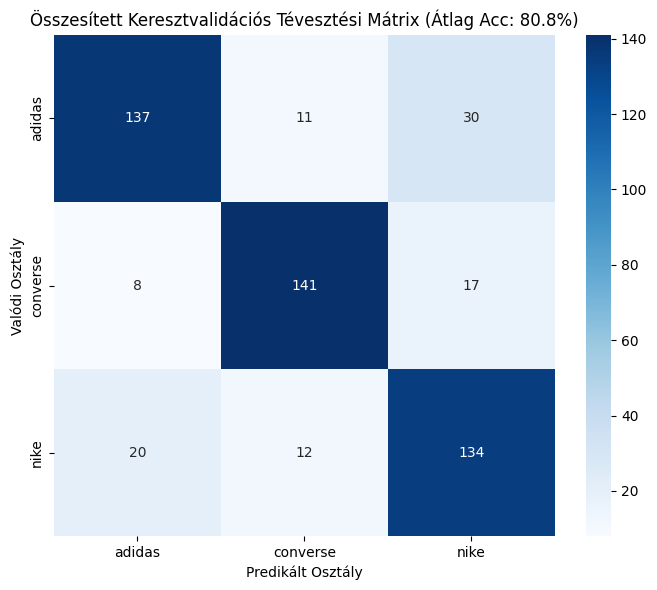

Classification Report a teljes validációra:
              precision    recall  f1-score   support

      adidas       0.83      0.77      0.80       178
    converse       0.86      0.85      0.85       166
        nike       0.74      0.81      0.77       166

    accuracy                           0.81       510
   macro avg       0.81      0.81      0.81       510
weighted avg       0.81      0.81      0.81       510



In [8]:
class_labels = list(train_generator.class_indices.keys())
cm = confusion_matrix(all_val_targets, all_val_predictions)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
plt.title(f"Összesített Keresztvalidációs Tévesztési Mátrix (Átlag Acc: {mean_acc*100:.1f}%)")
plt.xlabel("Predikált Osztály")
plt.ylabel("Valódi Osztály")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "confusion_matrix_cv_brand.png")
plt.show()

print("Classification Report a teljes validációra:")
print(classification_report(all_val_targets, all_val_predictions, target_names=class_labels))


Független teszt képek száma: 90
Found 90 validated image filenames belonging to 3 classes.
Teszteléshez betöltött legkiemelkedőbb modell: Fold 1 (best_model_fold_1.keras)
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 507ms/step

     VÉGSŐ TESZT ADATHALMAZ EREDMÉNYEK     
Teszt Accuracy: 0.7667
Teszt Macro F1: 0.7686

Classification Report (Teszt Készlet):
              precision    recall  f1-score   support

      adidas       0.71      0.78      0.75        32
    converse       0.93      0.86      0.89        29
        nike       0.68      0.66      0.67        29

    accuracy                           0.77        90
   macro avg       0.77      0.77      0.77        90
weighted avg       0.77      0.77      0.77        90



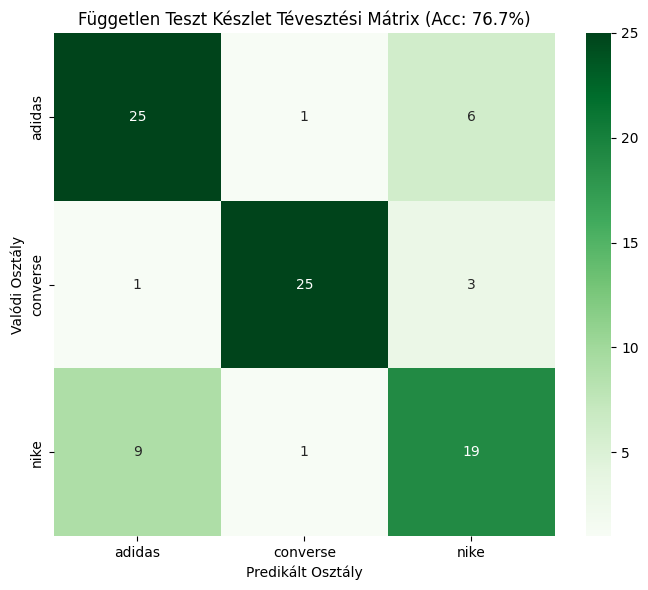

Teszt eredmények elmentve: results/test_results_brand.json


In [ ]:
# ==============================================================================
# 6. Független Holdout Teszt Adathalmaz Kiértékelése
# ==============================================================================

# 1. Teszt adatsor kinyerése a manifestből (is_test == True)
test_df = manifest[manifest["is_test"] == True].copy()
print(f"\nFüggetlen teszt képek száma: {len(test_df)}")

test_generator = val_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="path",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# 2. Kiválasztjuk a legmagasabb validációs pontosságú (Accuracy) fold modellt
best_fold_idx = int(results_df.loc[results_df['accuracy'].idxmax()]['fold']) - 1
best_model_path = MODEL_SAVE_DIR / f"best_model_fold_{2}.keras"
print(f"Teszteléshez betöltött legkiemelkedőbb modell: Fold {best_fold_idx + 1} ({best_model_path.name})")

best_model = models.load_model(best_model_path)

# 3. Predikció a teszt adatsoron
test_generator.reset()
test_preds_prob = best_model.predict(test_generator, verbose=1)
test_preds = np.argmax(test_preds_prob, axis=1)
test_true = test_generator.classes

# 4. Teszt jósági mutatók kiszámítása
test_acc = accuracy_score(test_true, test_preds)
test_f1 = f1_score(test_true, test_preds, average='macro')

print("\n=========================================")
print(f"     VÉGSŐ TESZT ADATHALMAZ EREDMÉNYEK     ")
print("=========================================")
print(f"Teszt Accuracy: {test_acc:.4f}")
print(f"Teszt Macro F1: {test_f1:.4f}")

# 5. Classification Report és Tévesztési Mátrix a teszt adatokra
print("\nClassification Report (Teszt Készlet):")
print(classification_report(test_true, test_preds, target_names=class_labels))

test_cm = confusion_matrix(test_true, test_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Greens", xticklabels=class_labels, yticklabels=class_labels)
plt.title(f"Független Teszt Készlet Tévesztési Mátrix (Acc: {test_acc*100:.1f}%)")
plt.xlabel("Predikált Osztály")
plt.ylabel("Valódi Osztály")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "confusion_matrix_test_brand.png")
plt.show()

# 6. Eredmények kimentése JSON fájlba
test_results_summary = {
    'best_fold_used': best_fold_idx + 1,
    'test_accuracy': float(test_acc),
    'test_macro_f1': float(test_f1),
    'test_samples_count': int(len(test_df))
}

with open(PROJECT_ROOT / "results" / "test_results_brand.json", "w", encoding="utf-8") as f:
    json.dump(test_results_summary, f, ensure_ascii=False, indent=4)
print("Teszt eredmények elmentve: results/test_results_brand.json")